# 05 — (α, ε) Robustness Heatmap

For each method on the stochastic corridor cliff (the hardest env),
build a 2D heatmap of performance vs α and ε. Shows which methods are
robust to hyperparameter tuning vs fragile.

Run at N_RUNS=50 even in overnight mode — heatmaps don't need tight SEM
since the relative pattern is what matters.


In [1]:
import sys, os, time
sys.path.insert(0, '..')
import numpy as np
import matplotlib.pyplot as plt

from envs import (CliffWalking, StochasticCliff,
                  CorridorCliff, StochasticCorridorCliff)
from agents import (run_sarsa, run_q_learning, run_expected_sarsa,
                    run_double_expected_sarsa, run_rr_expected_sarsa)
from utils import (multi_seed_run, smooth,
                   bootstrap_mean_ci, bootstrap_diff_ci, pairwise_table,
                   rollout_metrics, regret_to_convergence)

# ---- Run configuration ----
# Set N_RUNS=50 for pilot, bump to 500 for final overnight run
N_RUNS = 50
N_EPISODES = 100
EPS_DEFAULT = 0.1
ALPHA_DEFAULT = 0.3
SLIP = 0.2
RR_DELTA = 1.0   # RR-ES regret threshold used in most experiments

def sem(arr, axis=0):
    return arr.std(axis=axis, ddof=1) / np.sqrt(arr.shape[axis])

# ---- Environment factories ----
def env_det(seed=None):   return CliffWalking()
def env_stoch(seed=None): return StochasticCliff(slip_prob=SLIP, rng_seed=seed)
def env_corr(seed=None):  return CorridorCliff()
def env_scor(seed=None):  return StochasticCorridorCliff(slip_prob=SLIP, rng_seed=seed)

ENVS = {
    'Det Cliff':        env_det,
    'Stoch Cliff':      env_stoch,
    'Corr Cliff':       env_corr,
    'Stoch Corr Cliff': env_scor,
}

# ---- Method registry ----
METHODS = {
    'SARSA':          (run_sarsa,                {}),
    'Q-learning':     (run_q_learning,           {}),
    'Expected SARSA': (run_expected_sarsa,       {}),
    'Double ES':      (run_double_expected_sarsa, {}),
    f'RR-ES (δ={RR_DELTA})': (run_rr_expected_sarsa, {'delta': RR_DELTA}),
}

METHOD_COLORS = {
    'SARSA':              '#1f77b4',
    'Q-learning':         '#ff7f0e',
    'Expected SARSA':     '#2ca02c',
    'Double ES':          '#9467bd',
    f'RR-ES (δ={RR_DELTA})': '#d62728',
}
METHOD_MARKERS = {
    'SARSA':              'o',
    'Q-learning':         's',
    'Expected SARSA':     '^',
    'Double ES':          'v',
    f'RR-ES (δ={RR_DELTA})': 'D',
}

# override N_RUNS for this notebook only (heatmaps are expensive)
N_RUNS_HEATMAP = 50

ALPHAS = np.array([0.1, 0.2, 0.3, 0.5, 0.7, 0.9])
EPS_VALUES = np.array([0.05, 0.1, 0.15, 0.2, 0.3])

HEATMAP_ENV = 'Stoch Corr Cliff'
env_fn = ENVS[HEATMAP_ENV]


In [2]:
heatmaps = {name: np.zeros((len(EPS_VALUES), len(ALPHAS))) for name in METHODS}

t0 = time.time()
for name, (fn, kw) in METHODS.items():
    print(f'\n=== {name} ===')
    for i, eps in enumerate(EPS_VALUES):
        for j, a in enumerate(ALPHAS):
            ret = multi_seed_run(fn, env_fn, N_RUNS_HEATMAP, N_EPISODES,
                                 alpha=a, eps=eps,
                                 progress=False, **kw)
            heatmaps[name][i, j] = ret[:, -30:].mean()
        print(f'  eps={eps} done ({time.time()-t0:.0f}s)')
print(f'total: {time.time()-t0:.0f}s')



=== SARSA ===
  eps=0.05 done (22s)
  eps=0.1 done (46s)
  eps=0.15 done (70s)
  eps=0.2 done (96s)
  eps=0.3 done (125s)

=== Q-learning ===
  eps=0.05 done (147s)
  eps=0.1 done (169s)
  eps=0.15 done (191s)
  eps=0.2 done (214s)
  eps=0.3 done (237s)

=== Expected SARSA ===
  eps=0.05 done (269s)
  eps=0.1 done (301s)
  eps=0.15 done (331s)
  eps=0.2 done (362s)
  eps=0.3 done (393s)

=== Double ES ===
  eps=0.05 done (437s)
  eps=0.1 done (482s)
  eps=0.15 done (526s)
  eps=0.2 done (570s)
  eps=0.3 done (614s)

=== RR-ES (δ=1.0) ===
  eps=0.05 done (654s)
  eps=0.1 done (694s)
  eps=0.15 done (736s)
  eps=0.2 done (780s)
  eps=0.3 done (825s)
total: 825s


In [3]:
safe = lambda s: s.replace(' ', '_').replace('(','').replace(')','').replace('=','_').replace('δ','delta')
np.savez('../results/data/05_heatmap.npz',
         alphas=ALPHAS, eps_values=EPS_VALUES, env=HEATMAP_ENV, n_runs=N_RUNS_HEATMAP,
         **{safe(name): hm for name, hm in heatmaps.items()})
print('saved')


saved


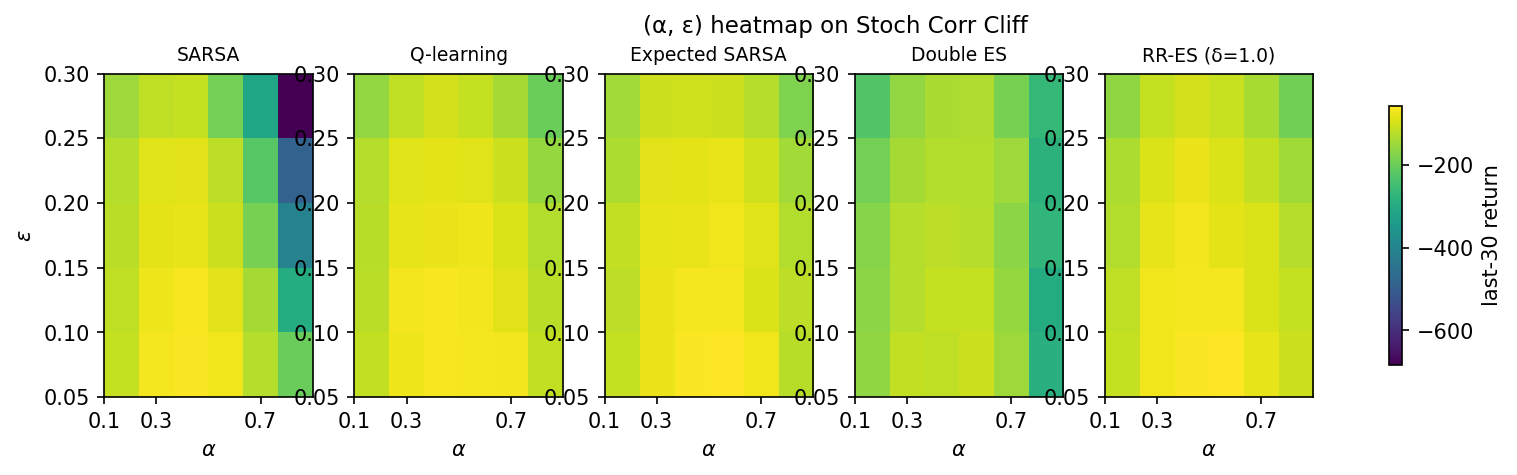

In [4]:
vmin = min(hm.min() for hm in heatmaps.values())
vmax = max(hm.max() for hm in heatmaps.values())

fig, axes = plt.subplots(1, 5, figsize=(13, 2.8), dpi=150,
                         gridspec_kw={'width_ratios': [1, 1, 1, 1, 1]})
for ax, (name, hm) in zip(axes, heatmaps.items()):
    im = ax.imshow(hm, aspect='auto', cmap='viridis', vmin=vmin, vmax=vmax,
                   origin='lower',
                   extent=[ALPHAS[0], ALPHAS[-1], EPS_VALUES[0], EPS_VALUES[-1]])
    ax.set_title(name, fontsize=9)
    ax.set_xlabel(r'$\alpha$')
    ax.set_xticks(ALPHAS[::2])
axes[0].set_ylabel(r'$\varepsilon$')
fig.colorbar(im, ax=axes, shrink=0.8, label='last-30 return')
plt.suptitle(f'(α, ε) heatmap on {HEATMAP_ENV}', y=1.02, fontsize=11)
plt.savefig('../results/figures/05_heatmap.png', dpi=200, bbox_inches='tight')
plt.show()


### Interpretation guide

- **Broad bright region** = robust to hyperparameter choice (good)
- **Narrow bright spot** = fragile, needs tuning (bad)
- **Methods with similar peaks but different footprints** tell you about *tunability*, not just peak performance
